# 01. Наша LogisticRegression vs sklearn
**Вопрос**: работает ли наша модель также хорошо, как готовая из sklearn?

In [17]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as SkLR

from model.classification.logistic_regression import LogisticRegression

In [18]:
X, y = make_classification(
    n_samples=1000,
    n_features=5,
    random_state=42,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(800, 5) (200, 5)
0.5 0.5


In [21]:
ours = LogisticRegression(learning_rate=0.1, n_iters=1000)
ours.fit(X_train, y_train)

sk = SkLR()
sk.fit(X_train, y_train)

print("наши веса:       ", ours.weights.round(2), ours.bias.round(2))
print("sklearn веса:    ", sk.coef_[0].round(2), sk.intercept_[0].round(2))

наши веса:        [ 1.55 -0.45  0.03 -0.72 -0.57] 0.26
sklearn веса:     [ 1.53 -0.44  0.03 -0.71 -0.56] 0.26


accuracy  наша: 0.84  sklearn: 0.84
log loss  наша: 0.3761  sklearn: 0.3758


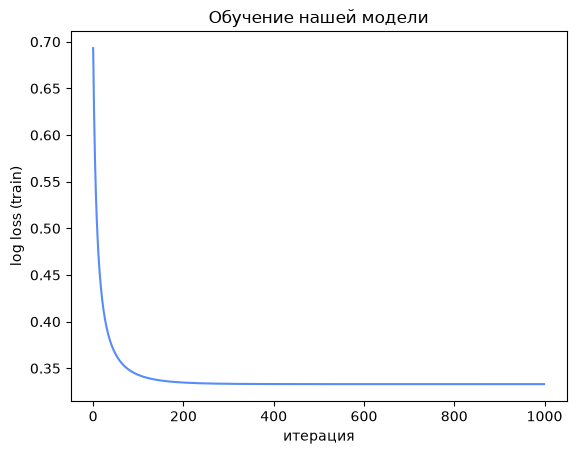

In [23]:
from losses.classification.log_loss import log_loss

p_ours = ours.predict_proba(X_test)
p_sk = sk.predict_proba(X_test)[:, 1]

print("accuracy  наша:", (ours.predict(X_test) == y_test).mean(), " sklearn:", (sk.predict(X_test) == y_test).mean())
print("log loss  наша:", round(log_loss(y_test, p_ours), 4), " sklearn:", round(log_loss(y_test, p_sk), 4))

plt.plot(ours.losses)
plt.xlabel("итерация")
plt.ylabel("log loss (train)")
plt.title("Обучение нашей модели")
plt.show()